# Week 6 — Data preparation, EDA and baseline
**Project P8 — Multilingual Public Grievance Classifier and Router** (CS474)

This notebook covers the Week 6 checklist: cleaning summary, train/validation/test split, exploratory analysis
(distributions, language coverage, correlations) and the first baseline model with its metrics.

> **Data provenance.** The training data in the repo is a team-generated set of English/Hindi/Marathi complaints
> (`label_source=generated`, see `docs/DATA.md`). Scores on a split drawn from it overstate real-world accuracy, so
> section 8 also checks the baseline on real text (BBMP phrases) when that file is available.
> Re-run this notebook after the real data is added to `data/raw/`.

In [1]:
import json, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency
from sklearn.metrics import accuracy_score, f1_score, classification_report

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from grievance.data.preprocess import load_and_split
from grievance.models.baseline import build_baseline
from grievance.models.evaluate import per_language_report, department_confusion_matrix
from grievance.data.urgency_rules import weak_urgency, weak_sentiment
from grievance.labels import DEPARTMENTS, URGENCY, SENTIMENT

DATA = ROOT / "data/processed/grievances.csv"
if not DATA.exists():
    DATA = ROOT / "data/samples/grievances_sample.csv"
    print("processed data not found -> using the repeated demo sample (illustrative only)")
df = pd.read_csv(DATA)
print("using:", DATA.relative_to(ROOT), "| rows:", len(df))
df.head()

using: data/processed/grievances.csv | rows: 1000


,text,language,department,urgency,sentiment,label_source
0,जवळच्या उद्यानातील झाडांची छाटणी झालेली नाही. ...,mr,other,high,negative,generated
1,सड़क मरम्मत के अनुरोध के लिए किससे संपर्क करें?,hi,roads,low,neutral,generated
2,The public water tap near our lane drips conti...,en,water,high,negative,generated
3,The street light timer is faulty and the lamp ...,en,power,medium,negative,generated
4,अवैध निर्माण से हमारी गली का रास्ता बंद हो गया...,hi,other,high,negative,generated


## 1. Cleaning summary

In [2]:
card = DATA.with_name("data_card.json")
if card.exists():
    c = json.loads(card.read_text())
    print({k: v for k, v in c.items() if not k.startswith("by_") and k != "warnings"})
    for w in c.get("warnings", []): print("WARNING:", w)
else:
    print("no data card (demo sample)")
print()
print("missing values:\n", df.isna().sum().to_string())
print("\nduplicate texts:", int(df["text"].duplicated().sum()))
print("invalid department labels:", int((~df.department.isin(DEPARTMENTS)).sum()))
print("invalid urgency labels:   ", int((~df.urgency.isin(URGENCY)).sum()))
print("invalid sentiment labels: ", int((~df.sentiment.isin(SENTIMENT)).sum()))
if "label_source" in df: print("\nlabel_source:\n", df.label_source.value_counts().to_string())

{'rows_in': 1000, 'dropped_too_short': 0, 'dropped_duplicates': 0, 'dropped_missing_department': 0, 'unknown_department_mapped_to_other': 0, 'urgency_weak_labelled': 0, 'sentiment_weak_labelled': 0, 'rows_out': 1000}

missing values:
 text            0
language        0
department      0
urgency         0
sentiment       0
label_source    0

duplicate texts: 0
invalid department labels: 0
invalid urgency labels:    0
invalid sentiment labels:  0

label_source:
 label_source
generated    1000


## 2. Label distributions

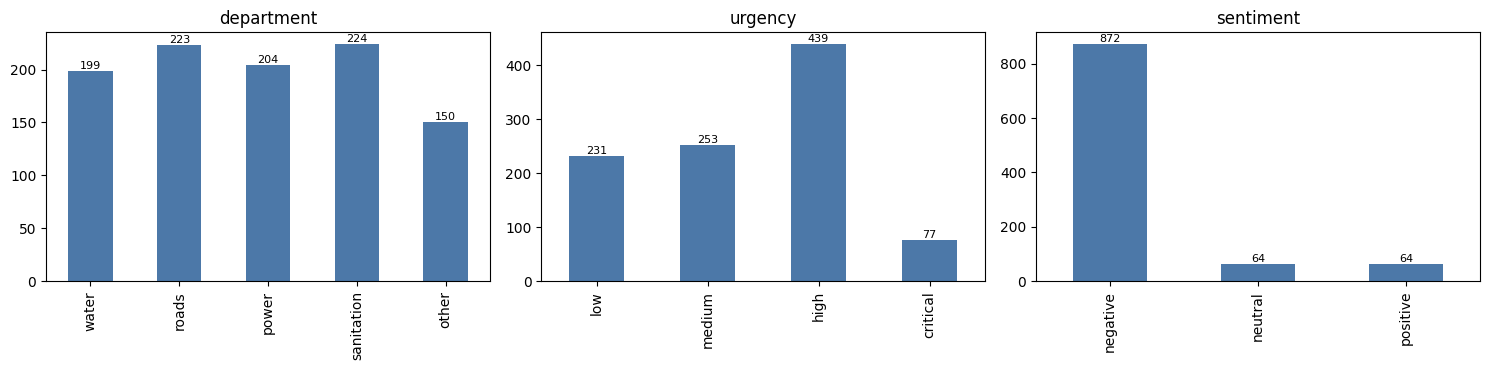

department
water         19.9
roads         22.3
power         20.4
sanitation    22.4
other         15.0


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, col, order in zip(ax, ["department", "urgency", "sentiment"], [DEPARTMENTS, URGENCY, SENTIMENT]):
    vc = df[col].value_counts().reindex(order).fillna(0)
    vc.plot.bar(ax=a, color="#4C78A8", title=col); a.set_xlabel("")
    for i, v in enumerate(vc): a.text(i, v, int(v), ha="center", va="bottom", fontsize=8)
plt.tight_layout(); plt.show()
print((df.department.value_counts(normalize=True).reindex(DEPARTMENTS) * 100).round(1).to_string())

## 3. Language coverage

language
en    420
hi    300
mr    280


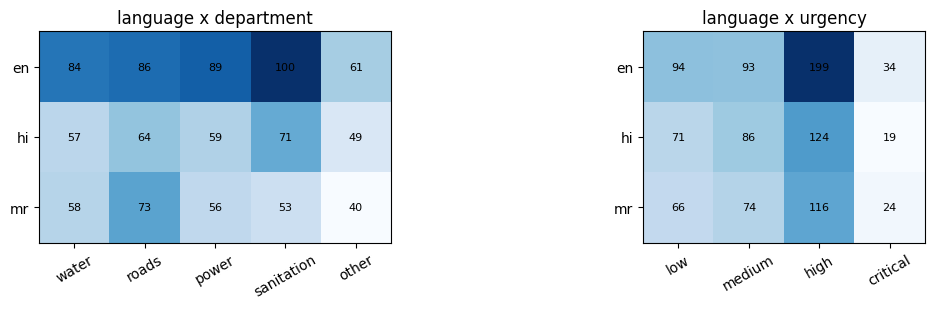

In [4]:
print(df.language.value_counts().to_string())
def heat(ct, title, ax):
    im = ax.imshow(ct.values, cmap="Blues"); ax.set_title(title)
    ax.set_xticks(range(ct.shape[1])); ax.set_xticklabels(ct.columns, rotation=30)
    ax.set_yticks(range(ct.shape[0])); ax.set_yticklabels(ct.index)
    for i in range(ct.shape[0]):
        for j in range(ct.shape[1]): ax.text(j, i, ct.values[i, j], ha="center", va="center", fontsize=8)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
heat(pd.crosstab(df.language, df.department)[DEPARTMENTS], "language x department", ax[0])
heat(pd.crosstab(df.language, df.urgency)[URGENCY], "language x urgency", ax[1])
plt.tight_layout(); plt.show()

## 4. Text length

language          en     hi     mr
n_chars count  420.0  300.0  280.0
        mean   110.7   99.0   99.0
        std     33.9   30.8   33.0
        min     41.0   25.0   26.0
        25%     83.0   76.0   75.8
        50%    112.0   99.0   96.0
        75%    134.0  121.0  122.0
        max    195.0  187.0  185.0
n_words count  420.0  300.0  280.0
        mean    20.5   21.0   16.3
        std      6.5    6.8    5.9
        min      7.0    7.0    5.0
        25%     15.0   16.0   11.0
        50%     20.0   21.0   16.0
        75%     25.0   26.0   21.0
        max     38.0   40.0   31.0


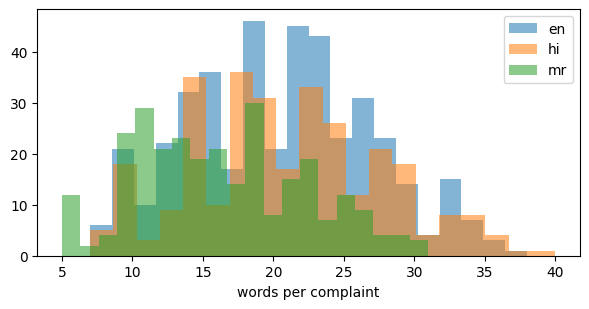

In [5]:
df["n_chars"] = df.text.str.len(); df["n_words"] = df.text.str.split().str.len()
print(df.groupby("language")[["n_chars", "n_words"]].describe().round(1).T.to_string())
fig, ax = plt.subplots(figsize=(7, 3.2))
for lang, g in df.groupby("language"): ax.hist(g.n_words, bins=20, alpha=.55, label=lang)
ax.set_xlabel("words per complaint"); ax.legend(); plt.show()

## 5. Patterns and correlations
Cramér's V measures association between two categorical columns (0 = none, 1 = perfect).

In [6]:
def cramers_v(a, b):
    ct = pd.crosstab(a, b); chi2 = chi2_contingency(ct)[0]; n = ct.values.sum()
    return float(np.sqrt((chi2 / n) / (min(ct.shape) - 1)))
pairs = [("department", "urgency"), ("department", "sentiment"), ("urgency", "sentiment"),
         ("language", "department"), ("language", "urgency")]
print(pd.Series({f"{a} ~ {b}": round(cramers_v(df[a], df[b]), 3) for a, b in pairs}).to_string())
print("\nurgency share within each department (%):")
print((pd.crosstab(df.department, df.urgency, normalize="index")[URGENCY] * 100).round(1).to_string())
print("\nsentiment share within each urgency level (%):")
print((pd.crosstab(df.urgency, df.sentiment, normalize="index") * 100).round(1).to_string())

department ~ urgency      0.042
department ~ sentiment    0.050
urgency ~ sentiment       0.494
language ~ department     0.053
language ~ urgency        0.057

urgency share within each department (%):
urgency      low  medium  high  critical
department                              
other       20.7    24.0  47.3       8.0
power       25.5    27.0  41.2       6.4
roads       22.4    22.9  46.2       8.5
sanitation  23.2    28.6  40.6       7.6
water       23.1    23.6  45.2       8.0

sentiment share within each urgency level (%):
sentiment  negative  neutral  positive
urgency                               
critical      100.0      0.0       0.0
high          100.0      0.0       0.0
low            44.6     27.7      27.7
medium        100.0      0.0       0.0


## 6. Train / validation / test split
70 / 15 / 15, stratified by department, seed 42 (same call every script uses).

In [7]:
train, val, test = load_and_split(DATA, seed=42)
print({"train": len(train), "val": len(val), "test": len(test)})
share = pd.DataFrame({n: s.department.value_counts(normalize=True) for n, s in [("train", train), ("val", val), ("test", test)]}).reindex(DEPARTMENTS)
print((share * 100).round(1).to_string())
print("\nlanguages in each split:", {n: s.language.nunique() for n, s in [("train", train), ("val", val), ("test", test)]})
print("train/test text overlap:", len(set(train.text) & set(test.text)))

{'train': 700, 'val': 150, 'test': 150}
            train   val  test
department                   
water        19.9  20.0  20.0
roads        22.3  22.0  22.7
power        20.4  20.7  20.0
sanitation   22.4  22.7  22.0
other        15.0  14.7  15.3

languages in each split: {'train': 3, 'val': 3, 'test': 3}
train/test text overlap: 0


## 7. Baseline: TF-IDF (word 1-2 grams) + logistic regression (class-weighted)

validation accuracy: 0.9933
test accuracy:       0.9667
test macro-F1:       0.9686

              precision    recall  f1-score   support

       other       1.00      1.00      1.00        23
       power       1.00      1.00      1.00        30
       roads       1.00      0.97      0.99        34
  sanitation       0.97      0.88      0.92        33
       water       0.88      1.00      0.94        30

    accuracy                           0.97       150
   macro avg       0.97      0.97      0.97       150
weighted avg       0.97      0.97      0.97       150

language  n  accuracy  macro_f1
      en 51    1.0000    1.0000
      hi 62    0.9194    0.9295
      mr 37    1.0000    1.0000


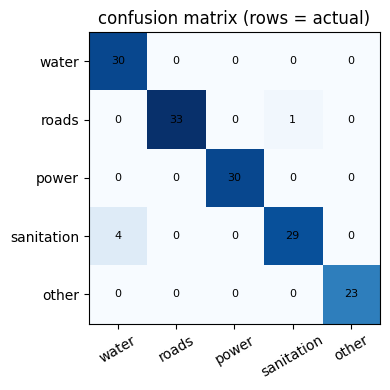

In [8]:
model = build_baseline().fit(train.text, train.department)
test = test.assign(pred=model.predict(test.text))
print("validation accuracy:", round(accuracy_score(val.department, model.predict(val.text)), 4))
print("test accuracy:      ", round(accuracy_score(test.department, test.pred), 4))
print("test macro-F1:      ", round(f1_score(test.department, test.pred, average="macro"), 4))
print()
print(classification_report(test.department, test.pred, zero_division=0))
print(per_language_report(test, "department", "pred").round(4).to_string(index=False))
cm = department_confusion_matrix(test, "department", "pred")
fig, ax = plt.subplots(figsize=(4.8, 4)); heat(cm, "confusion matrix (rows = actual)", ax); plt.tight_layout(); plt.show()

In [9]:
# Urgency / sentiment: the keyword rules currently used by the API, scored against the dataset labels
for col, fn in [("urgency", weak_urgency), ("sentiment", weak_sentiment)]:
    p = test.text.map(fn)
    print(f"rule baseline {col}: accuracy={accuracy_score(test[col], p):.3f}  macro-F1={f1_score(test[col], p, average='macro', zero_division=0):.3f}")

rule baseline urgency: accuracy=0.473  macro-F1=0.471
rule baseline sentiment: accuracy=0.233  macro-F1=0.156


## 8. Check on real text (BBMP complaint phrases)
Skipped automatically when `data/raw/bbmp/bbmp_seed.csv` is absent. The BBMP export has only ~190 distinct phrases and its category-to-department mapping is itself noisy, so treat this as a sanity check, not a benchmark.

In [10]:
seed_path = ROOT / "data/raw/bbmp/bbmp_seed.csv"
if seed_path.exists():
    seed = pd.read_csv(seed_path); seed["pred"] = model.predict(seed.text)
    core = seed[seed.department != "other"]
    print(f"all {len(seed)} distinct phrases:      accuracy {(seed.pred == seed.department).mean():.2f}")
    print(f"{len(core)} non-'other' phrases:        accuracy {(core.pred == core.department).mean():.2f}")
    w = ((core.pred == core.department) * core["count"]).sum() / core["count"].sum()
    print(f"non-'other', weighted by frequency: accuracy {w:.2f}")
    print("\nmost frequent mistakes:")
    print(core[core.pred != core.department].sort_values("count", ascending=False).head(8)[["text", "department", "pred", "count"]].to_string(index=False))
else:
    print("BBMP seed not found; skipping the real-text check.")

all 186 distinct phrases:      accuracy 0.41
38 non-'other' phrases:        accuracy 0.55
non-'other', weighted by frequency: accuracy 0.91

most frequent mistakes:
                                                                   text department       pred  count
                                 Debris Removal / Construction Material      roads      other  24785
                                                         Dead animal(s) sanitation      power  13082
                                                       water stagnation      roads      water  11184
                                      Requirement For New Street Lights      power sanitation   9996
Complaint against SW collector/ SWM official for violation of SWM Rules sanitation      other   6532
                                                     Maintenance of SWD      water      other   5028
                                             UnAuthorised Constructions      roads      power   4809
                           

## 9. Takeaways
- **Cleaning:** every row has valid labels and a unique text; the pipeline drops empties, duplicates and too-short texts and writes a data card.
- **Balance:** departments are roughly balanced here only because the generator weights them that way. Real data is far more skewed — in the BBMP export Electrical (35% of 1.23M rows), Solid Waste (29%) and Road Maintenance (14%) dominate — so class weighting and macro-F1 stay essential.
- **Languages:** English, Hindi and Marathi only. Per-language scores are on a few dozen test rows each, so they are noisy; Bengali and other languages (BanglaPSG, IndicSentiment) are not yet in the training data.
- **Correlations:** department, language and urgency are almost independent of each other (Cramér's V about 0.04-0.06), so urgency has to be learned from the wording (severity, duration, urgent phrasing), not from the department. The strong urgency-sentiment link (V about 0.49) is an artefact of the generator: every neutral and positive row is low-urgency, and all other rows are negative. Real data will not be this clean.
- **Baseline:** TF-IDF + logistic regression reaches ~97% on the generated test split, mostly because the text is templated. On real BBMP phrases it is far lower (see section 8), which is the honest signal for the next stage.
- **Urgency/sentiment:** the keyword rules are weak (about 47% urgency accuracy; they never predict *positive* sentiment) — the transformer heads must replace them.

**Next:** add real Hindi/Marathi/Bengali complaints, have native speakers review the generated rows, then fine-tune MuRIL / IndicBERT / mBERT and compare against this baseline.